In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact
from matplotlib.widgets import RadioButtons, Slider
import seaborn as sns
%matplotlib widget

df = pd.read_excel("US-Superstore-data.xls")

# Display all column names
print(df.columns)

# Initial Exploration
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

# Remove Duplicate Rows
df = df.drop_duplicates()

# Standardize Column Names
# Remove extra spaces and replace spaces with underscores

df.columns = (
    df.columns
    .str.strip()
    .str.replace(" ", "_")
)

# Handle Missing Values
# Numerical columns: fill with median
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

# Categorical columns: fill with mode
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert Date Columns
date_cols = ["Order_Date", "Ship_Date"]

for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col])

# Remove Leading/Trailing Spaces from Text Columns
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

# Check Data Types
print("\nData Types:")
print(df.dtypes)

# Check for Remaining Missing Values
print("\nRemaining Missing Values:")
print(df.isnull().sum())

# Summary Statistics
print("\nSummary Statistics:")
print(df.describe())

# Save Cleaned Dataset
df.to_csv("US-Superstore-data-cleaned.csv", index=False)

print("\nCleaning complete.")

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')
Dataset Shape: (9994, 21)

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate Rows: 0

Data Types:
Row_ID                    int64
Order_ID                    str
Order_Date       datetime64[us]
Ship_Date        datetime64[us]
Ship_Mode                   str
Customer_ID                 str
Customer_Name 

C:\Users\USER1\AppData\Local\Temp\ipykernel_27196\2818428373.py:42: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns


            Row_ID                  Order_Date                   Ship_Date  \
count  9994.000000                        9994                        9994   
mean   4997.500000  2016-04-30 00:07:12.259355  2016-05-03 23:06:58.571142   
min       1.000000         2014-01-03 00:00:00         2014-01-07 00:00:00   
25%    2499.250000         2015-05-23 00:00:00         2015-05-27 00:00:00   
50%    4997.500000         2016-06-26 00:00:00         2016-06-29 00:00:00   
75%    7495.750000         2017-05-14 00:00:00         2017-05-18 00:00:00   
max    9994.000000         2017-12-30 00:00:00         2018-01-05 00:00:00   
std    2885.163629                         NaN                         NaN   

        Postal_Code         Sales     Quantity     Discount       Profit  
count   9994.000000   9994.000000  9994.000000  9994.000000  9994.000000  
mean   55190.379428    229.858001     3.789574     0.156203    28.656896  
min     1040.000000      0.444000     1.000000     0.000000 -6599.978000

In [2]:
print(df.columns.tolist()) #Print out the columns in order to have something to refer to later with column names when producing charts and doing analysis

['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub-Category', 'Product_Name', 'Sales', 'Quantity', 'Discount', 'Profit']


Selected Region: All


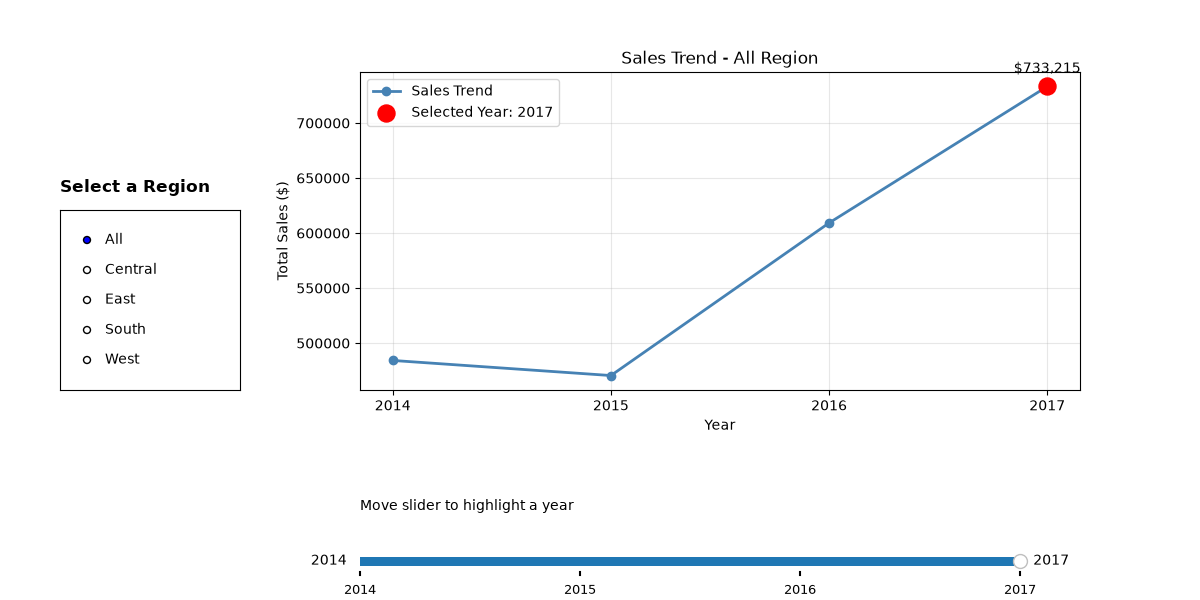

In [3]:
# DATA PREPARATION
# Remove leading/trailing spaces from column names
df.columns = df.columns.str.strip()

# Convert Order_Date column to datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Create Year column from Order_Date
df['Year'] = df['Order_Date'].dt.year

# Create list of regions for radio buttons
regions = ['All'] + sorted(df['Region'].unique())

# Get unique years from dataset
years = sorted(df['Year'].unique())

# Data visualisation using Matplotlib
fig, ax = plt.subplots(figsize=(12, 6))

# Make room for widgets
plt.subplots_adjust(left=0.30, bottom=0.35)

# RADIO BUTTONS

rax = plt.axes([0.05, 0.35, 0.15, 0.30])

radio = RadioButtons(
    rax,
    regions
)

# Add instruction text to figure
fig.text(
    0.05,
    0.68,
    "Select a Region",
    fontsize=12,
    fontweight='bold'
)

# YEAR SLIDER

sax = plt.axes([0.30, 0.05, 0.55, 0.03])

year_slider = Slider(
    ax=sax,
    label='2014',
    valmin=0,
    valmax=len(years) - 1,
    valinit=len(years) - 1,
    valstep=1
)
fig.text(
    0.30,
    0.15,
    "Move slider to highlight a year",
    fontsize=10
)

# Add year markers underneath slider

for i, year in enumerate(years):

    # Position relative to slider range
    xpos = i / (len(years) - 1)

    # Small tick mark
    sax.plot(
        [xpos, xpos],
        [-0.3, -0.1],
        transform=sax.transAxes,
        color='black',
        clip_on=False
    )

    # Year label
    sax.text(
        xpos,
        -0.8,
        str(year),
        transform=sax.transAxes,
        ha='center',
        va='top',
        fontsize=9
    )

# UPDATE CHART

def update(val):

    # Get currently selected region
    region = radio.value_selected
    print(f"Selected Region: {region}")

    # Convert slider position to actual year
    selected_year = years[int(year_slider.val)]

    # Display actual year in slider text
    year_slider.valtext.set_text(str(selected_year))

    # Filter data by region
    if region == 'All':
        filtered_df = df.copy()
    else:
        filtered_df = df[df['Region'] == region]

    # Calculate total sales for each year
    sales_by_year = (
        filtered_df
        .groupby('Year')['Sales']
        .sum()
        .reset_index()
        .sort_values('Year')
    )

    # Get the row corresponding to the selected year
    selected_data = sales_by_year[
        sales_by_year['Year'] == selected_year
    ]

    # Clear chart before redrawing
    ax.clear()

    # Draw trend line for all years
    ax.plot(
        sales_by_year['Year'],
        sales_by_year['Sales'],
        marker='o',
        linewidth=2,
        color='steelblue',
        label='Sales Trend'
    )

    # Highlight currently selected year
    if not selected_data.empty:
        ax.scatter(
            selected_data['Year'],
            selected_data['Sales'],
            color='red',
            s=150,
            zorder=5,
            label=f'Selected Year: {selected_year}'
        )

        # Add annotation showing sales value
        sales_value = selected_data['Sales'].iloc[0]

        ax.annotate(
            f'${sales_value:,.0f}',
            (
                selected_data['Year'].iloc[0],
                selected_data['Sales'].iloc[0]
            ),
            xytext=(0, 10),
            textcoords='offset points',
            ha='center'
        )

    # Show all years on x-axis
    ax.set_xticks(years)

    # Chart labels
    ax.set_title(f'Sales Trend - {region} Region')
    ax.set_xlabel('Year')
    ax.set_ylabel('Total Sales ($)')

    ax.grid(True, alpha=0.3)
    ax.legend()

    # Refresh chart
    fig.canvas.draw_idle()

    # Refresh chart
    fig.canvas.draw_idle()

# INITIAL CHART
update(None)

# CONNECT WIDGETS
radio.on_clicked(update)
year_slider.on_changed(update)

plt.show()

In [4]:
# Code to check that no spaces have been added into regions
print(df['Region'].unique())

# Clean Region values
df['Region'] = df['Region'].str.strip()

regions = ['All'] + sorted(df['Region'].unique())

<StringArray>
['South', 'West', 'Central', 'East']
Length: 4, dtype: str


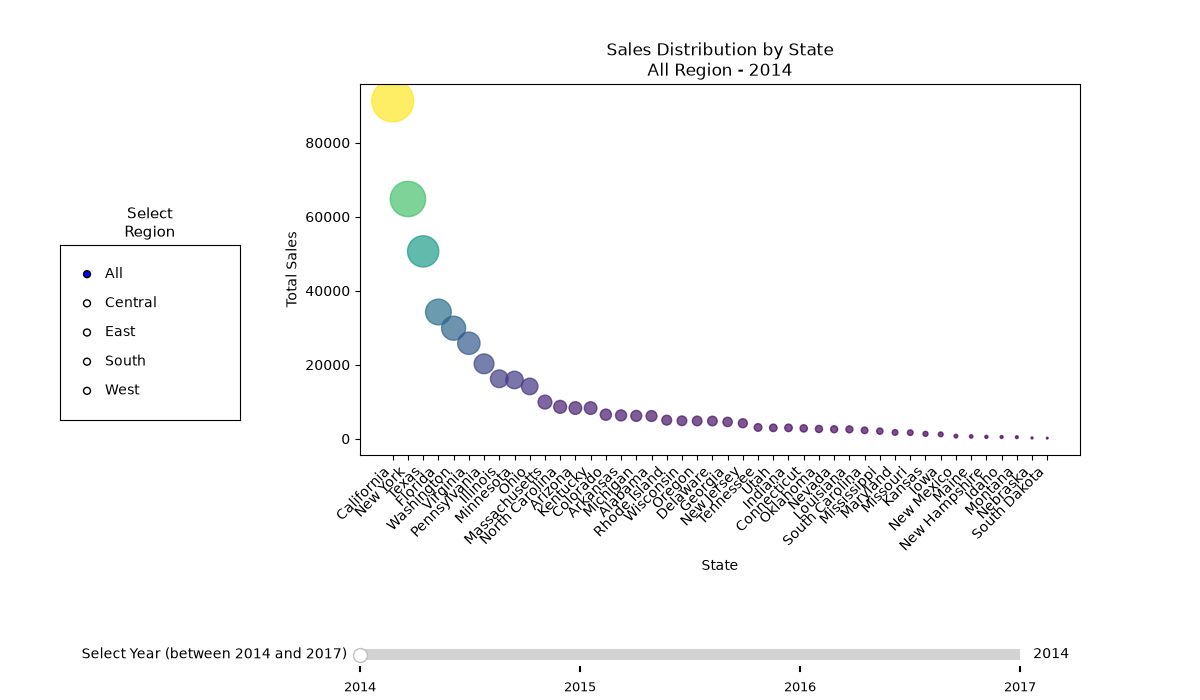

In [5]:
# DATA PREPARATION

df.columns = df.columns.str.strip()

df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df['Year'] = df['Order_Date'].dt.year

regions = ['All'] + sorted(df['Region'].unique())
years = sorted(df['Year'].unique())

# Interactive map visualising sales by state using Seaborn. Although the exercise says to go by country, as all the data is from the USA, this would not provide any useful insights, so doing this by state instead.
fig, ax = plt.subplots(figsize=(12, 7))

plt.subplots_adjust(
    left=0.30,
    bottom=0.35
)

# REGION RADIO BUTTONS

rax = plt.axes([0.05, 0.40, 0.15, 0.25])

rax.set_title(
    "Select\nRegion",
    fontsize=11
)

radio = RadioButtons(
    rax,
    regions
)

# YEAR SLIDER

sax = plt.axes([0.30, 0.05, 0.55, 0.03])

year_slider = Slider(
    ax=sax,
    label='Select Year (between 2014 and 2017)',
    valmin=0,
    valmax=len(years)-1,
    valinit=0,
    valstep=1
)

# Add year markers underneath slider

for i, year in enumerate(years):

    # Position relative to slider range
    xpos = i / (len(years) - 1)

    # Small tick mark
    sax.plot(
        [xpos, xpos],
        [-0.3, -0.1],
        transform=sax.transAxes,
        color='black',
        clip_on=False
    )

    # Year label
    sax.text(
        xpos,
        -0.8,
        str(year),
        transform=sax.transAxes,
        ha='center',
        va='top',
        fontsize=9
    )

# UPDATE FUNCTION

def update(val):

    region = radio.value_selected

    selected_year = years[int(year_slider.val)]

    year_slider.valtext.set_text(
        str(selected_year)
    )

    # Filter year
    filtered_df = df[
        df['Year'] == selected_year
    ]

    # Filter region
    if region != 'All':
        filtered_df = filtered_df[
            filtered_df['Region'] == region
        ]

    # Aggregate sales by country
    state_sales = (
        filtered_df
        .groupby('State')['Sales']
        .sum()
        .reset_index()
        .sort_values(
            by='Sales',
            ascending=False
        )
    )

    ax.clear()

    scatter = ax.scatter(
        x=range(len(state_sales)),
        y=state_sales['Sales'],
        s=state_sales['Sales'] / 100,
        c=state_sales['Sales'],
        cmap='viridis',
        alpha=0.7
    )

    ax.set_xticks(
        range(len(state_sales))
    )

    ax.set_xticklabels(
        state_sales['State'],
        rotation=45,
        ha='right'
    )

    ax.set_title(
        f'Sales Distribution by State\n'
        f'{region} Region - {selected_year}'
    )

    ax.set_xlabel('State')
    ax.set_ylabel('Total Sales')

    fig.canvas.draw_idle()

# INITIAL DRAW

update(None)

# LINK WIDGETS

radio.on_clicked(update)
year_slider.on_changed(update)

plt.show()

C:\Users\USER1\AppData\Local\Temp\ipykernel_27196\3638970083.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


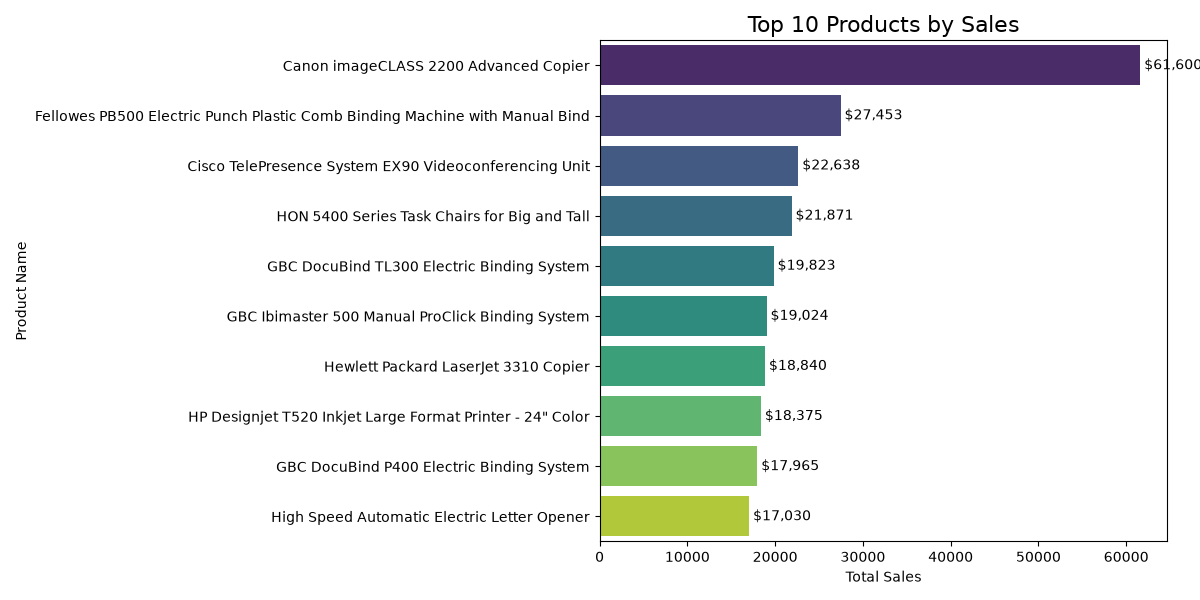

In [6]:
# Clean column names
df.columns = df.columns.str.strip()

# Calculate total sales for each product
top_products = (
    df.groupby('Product_Name')['Sales']
      .sum()
      .reset_index()
      .sort_values(by='Sales', ascending=False)
      .head(10)
)

# Create figure using Seaborn to show top 10 products by sales
plt.figure(figsize=(12, 6))

# Create bar chart
sns.barplot(
    data=top_products,
    x='Sales',
    y='Product_Name',
    palette='viridis'
)

# Add chart title and labels
plt.title('Top 10 Products by Sales', fontsize=16)
plt.xlabel('Total Sales')
plt.ylabel('Product Name')

# Add sales values to bars
for index, value in enumerate(top_products['Sales']):
    plt.text(
        value,
        index,
        f' ${value:,.0f}',
        va='center'
    )

plt.tight_layout()
plt.show()

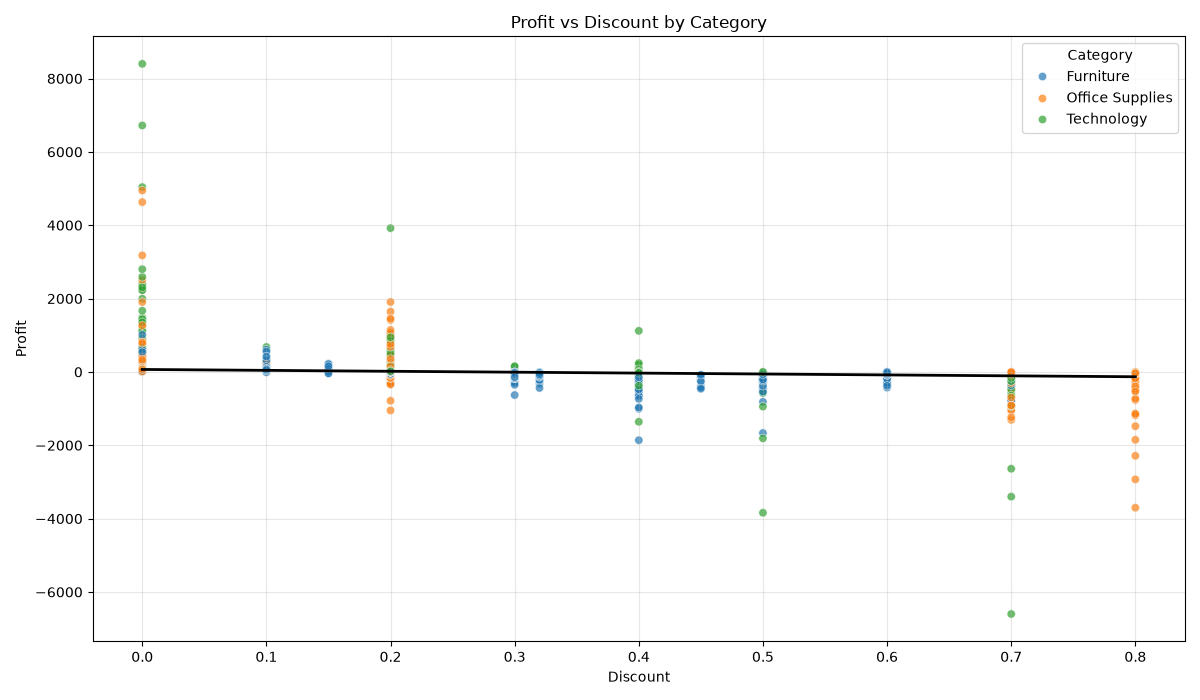

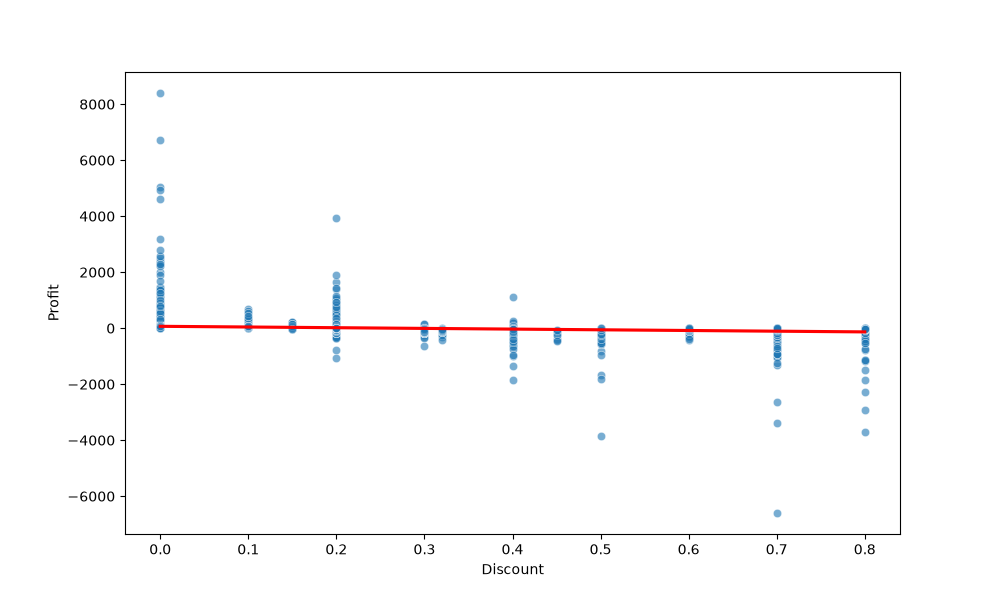

In [7]:
# Clean column names
df.columns = df.columns.str.strip()

# Create figure
plt.figure(figsize=(10, 6))

# Scatter plot analysing relationship between profit and discount.
sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    alpha=0.6
)

# Add a trend line
sns.regplot(
    data=df,
    x='Discount',
    y='Profit',
    scatter=False,
    color='red'
)

plt.figure(figsize=(12, 7))

# Scatter plot coloured by category
sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    hue='Category',
    alpha=0.7
)

# Optional trend line
sns.regplot(
    data=df,
    x='Discount',
    y='Profit',
    scatter=False,
    color='black',
    line_kws={'linewidth': 2}
)

# Formatting
plt.title('Profit vs Discount by Category')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Two charts above to compare different styles - the first one is better as it visualises the data in a clearer manner with more colours.

1. Comparison of Insights from Matplotlib and Seaborn Visualisations
Matplotlib Visualisations

The Matplotlib charts focused on interactivity and trend exploration:

Sales Trend by Region (2014-2017)

Key insights:
Sales increased significantly between 2015 and 2017.
2015 experienced a slight decline compared to 2014.
2017 was the strongest performing year, with total sales exceeding $733,000.
The radio buttons allowed comparison of regional performance, making it easier to identify regional sales patterns.
The year slider helped users focus on specific years while maintaining visibility of the overall trend.
Sales Distribution by State

Key insights:

Sales were highly concentrated in a small number of states.
California generated substantially more sales than any other state.
States such as New York, Texas, and Florida represented another strong sales tier.
Many states contributed only a small proportion of total sales, indicating an uneven distribution of revenue across locations.
Bubble size and colour intensity quickly highlighted high-performing states.

Seaborn Visualisations
The Seaborn charts focused more on statistical patterns and comparisons.

Top 10 Products by Sales
Key insights:A small number of products generated a large share of overall revenue.
Sales were concentrated among top-performing products rather than being evenly distributed across the catalogue.
Product rankings were immediately apparent through the ordered bar chart.
Profit vs Discount Scatter Plot

Key insights:
Higher discounts generally appeared to reduce profitability.
Many transactions with larger discounts generated lower profits or losses.
The inclusion of colour coding by category made it possible to compare behaviour across product categories.
The trend line highlighted the overall negative relationship between discount and profit.

2. Ease of Use and Effectiveness
Matplotlib
Strengths:
- Highly customisable.
- Excellent for creating dashboards and interactive controls.
- Supports widgets such as:
- Radio buttons
- Sliders
- Checkboxes
- Custom annotations
- Ideal when users need to explore data interactively.
Weaknesses:
- Requires significantly more code.
- Widget positioning can be difficult.
- More manual formatting is needed.
- Interactive elements depend on the plotting backend and may not work in all notebook environments.
Overall Impression
Matplotlib is best suited for custom analytical dashboards and interactive visualisations, but it requires more development effort.

Seaborn
Strengths:
- Much simpler syntax.
- Attractive visual styling by default.
- Excellent for statistical analysis and exploratory data analysis (EDA).
- Produces professional-looking charts with minimal code.
- Built directly on top of Matplotlib.
Weaknesses:
- Limited interactive capabilities.
- Less control over widget-based dashboard functionality.
- Complex customisation often requires dropping down into Matplotlib.
Overall Impression
Seaborn is best suited for quick data exploration and presenting statistical relationships. It is generally faster and easier to use for standard business visualisations.

Conclusion
Both libraries were effective but served different purposes:

The Matplotlib charts provided deeper exploration through interactivity, allowing users to investigate sales trends by region and year. The Seaborn charts were more effective for quickly identifying business insights such as top-selling products and the impact of discounts on profitability. Together, the two libraries provided a comprehensive view of sales performance, product success, geographic distribution, and profitability drivers.